In [15]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
import random
import json

e = 0.03 #relaxation threshold
k = 1.0 #spring constant
l = 1.5 #equilibrium distance this is initially 2 in the lattice but is set to 1 for the simulation
n = 100 # size of the array
fover = 1.1 #over relaxation scale

lattice = np.zeros([n,n,2,1]) #array with particle positions [0] = x, [1] = y
adjacent = np.zeros([n,n]).tolist() #array with list of neighbour particles
stress = np.zeros([n,n,3,1]) #sxx[0], syy[1], sxy[2] stress per particle 



#var = np.loadtxt("tests/variation.txt").reshape(50,100,100)
#var_i = 0 

In [16]:
def triangular():
    global lattice
    for i in range(n):
        for j in range(n):
            if (i%2==0 and j%2==0) or (i%2==1 and j%2==1):
                lattice[i][j][0] = i*math.sqrt(3)+2
                lattice[i][j][1] = j+2
triangular()

In [17]:
def adjacent_particles():
    global adjacent
    neighbours = [(-1,-1),(-1,1),(0,-2),(0,2),(1,-1),(1,1)]
    for i in range(2,n-2):
        for j in range(2,n-2):
            if lattice[i][j].all() != 0:
                adjacent[i][j] = []
                for nb in neighbours:
                    if (i+nb[0]>-1 and i+nb[0]<n) and (j+nb[1]>-1 and j+nb[1]<n):
                        if lattice[i+nb[0]][j+nb[1]].all() !=0:
                            adjacent[i][j].append((i+nb[0],j+nb[1]))
adjacent_particles()

In [18]:
def force(i, j): 
    global stress, lattice #this will allow you to access and modify the variables declared outside this function
    xx, yy, sxx, syy, sxy, anc = 0, 0, 0, 0, 0, 0 
    
# distance between 2 particles 

    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]
        dd = math.sqrt(dx**2 + dy**2)


        if (dd != 0):
            uxi = dx/dd
            uyi = dy/dd

        else:  
            uxi = 0.0
            uyi = 0.0

        fn = -k*(dd-l)
        fx = fn*uxi
        fy = fn*uyi
        
# overall force and stress
        xx = xx + fx
        yy = yy + fy
        sxx = sxx + fx*(l/2)*uxi
        syy = syy + fy*(l/2)*uyi
        sxy = sxy + fx*(l/2)*uyi
        anc = anc + k

    stress[i][j][0] = sxx
    stress[i][j][1] = syy
    stress[i][j][2] = sxy
    
# over relaxation step       
    
    anc = 1.0/anc
    xx = xx * anc        
    yy = yy * anc
        
    if (e < math.sqrt((xx*xx)+(yy*yy))): 
        lattice[i][j][0] = lattice[i][j][0] + xx * fover   
        lattice[i][j][1] = lattice[i][j][1] + yy * fover  
       

In [19]:
def run_simulation():
    for z in range(2): #number of time steps
        for i in range(2,n-2): # leaving the fixed borders out
            for j in range(2,n-2):
                if lattice[i][j].all()!=0:
                    force(i, j)

In [20]:
def fracturing(i,j):
    global mbreak, spring_to_break, spring_x, spring_y
    tb = 1
    ten_break = 0

    for nb in adjacent[i][j]:
        dx = lattice[i][j][0]-lattice[nb[0]][nb[1]][0]
        dy = lattice[i][j][1]-lattice[nb[0]][nb[1]][1]
        dd = math.sqrt(dx**2 + dy**2)
        
        fn = k*(dd-l)     
        
        if (fn >= 0.0):
            ten_break = (fn / tb) + random.randint(0,2)
            
        if (ten_break > 1.0): 
            if (ten_break > mbreak):  
                mbreak = ten_break 
                spring_to_break = nb
                spring_x = i
                spring_y = j

/tmp/ipykernel_85/2303671644.py:10: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dd = math.sqrt(dx**2 + dy**2)
/tmp/ipykernel_85/2303671644.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  if (e < math.sqrt((xx*xx)+(yy*yy))):
/tmp/ipykernel_85/1945449532.py:9: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  dd = math.sqrt(dx**2 + dy**2)


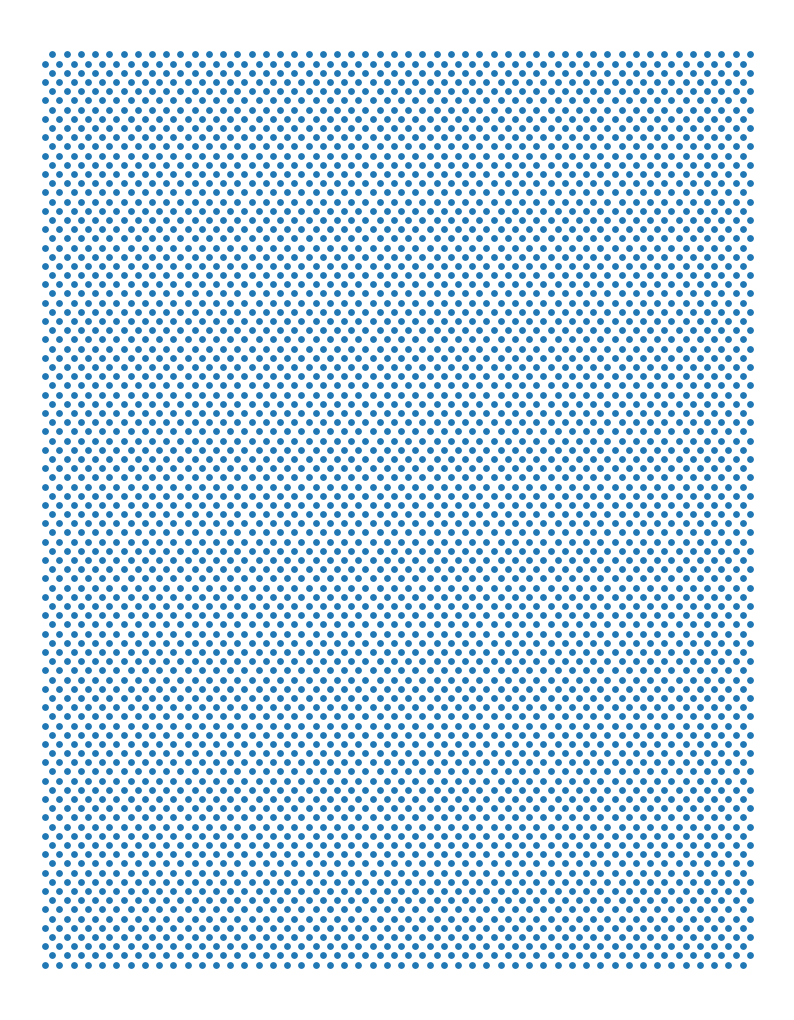

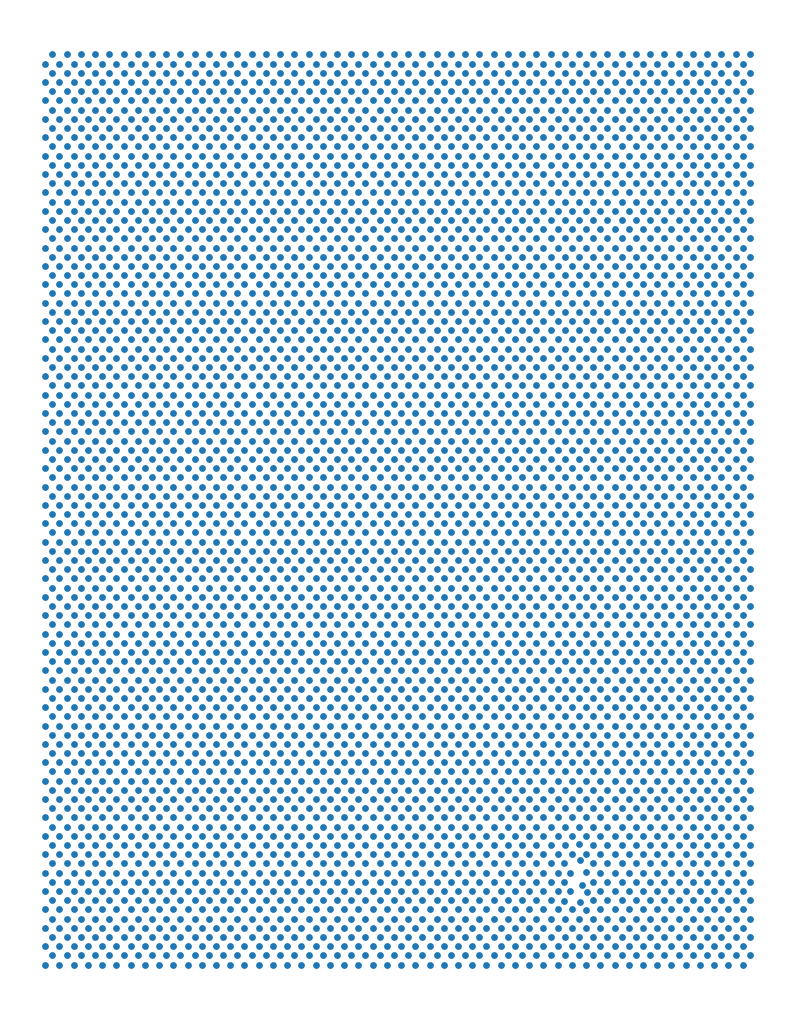

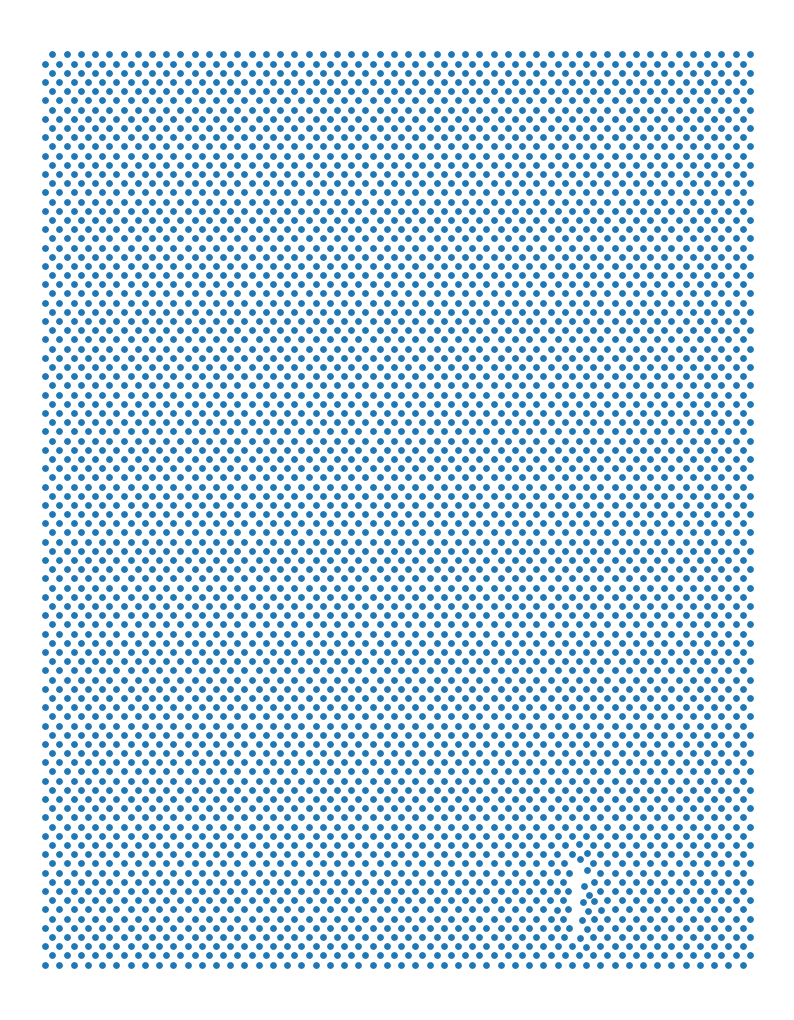

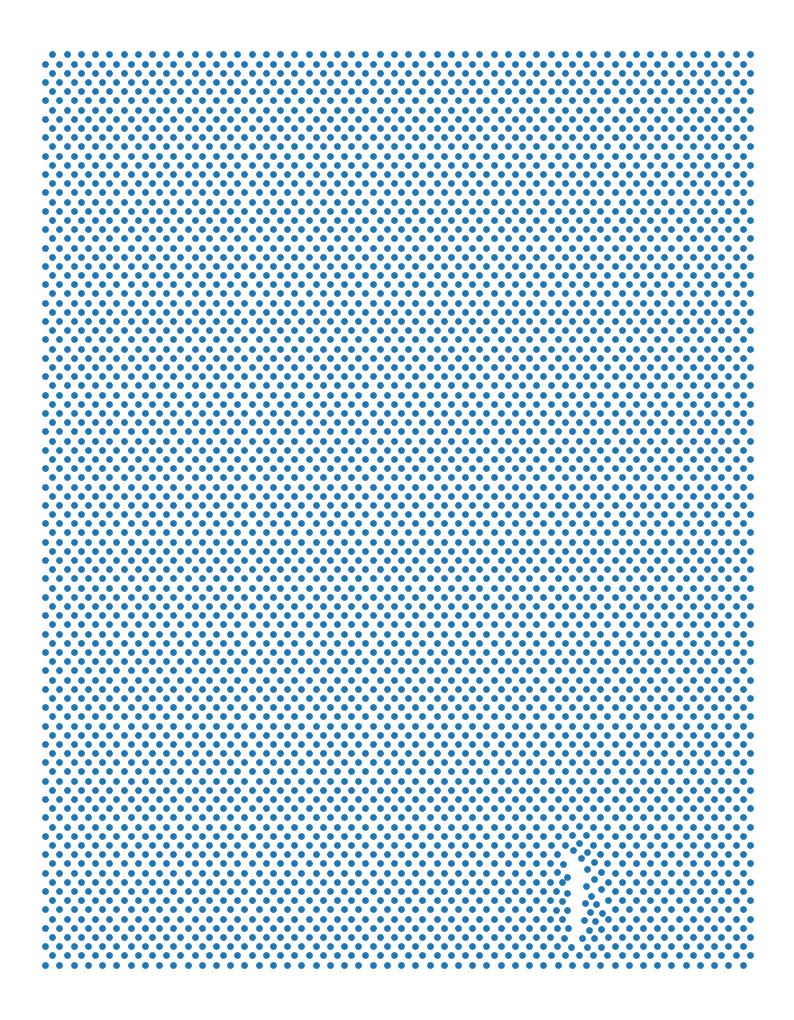

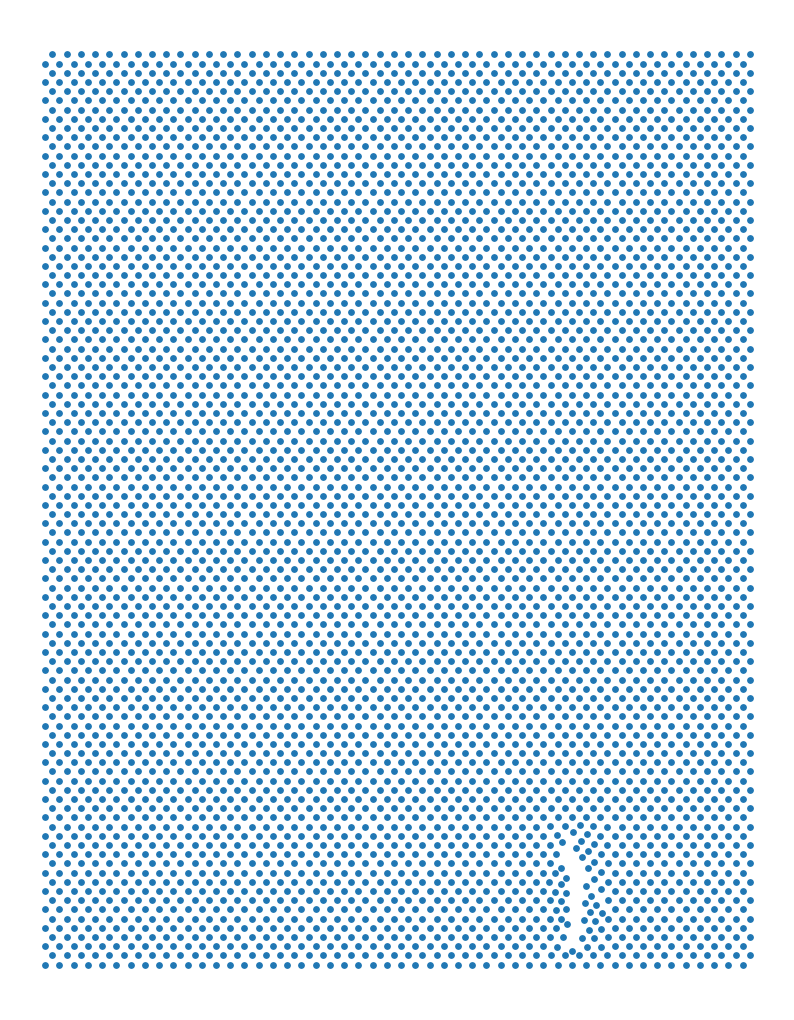

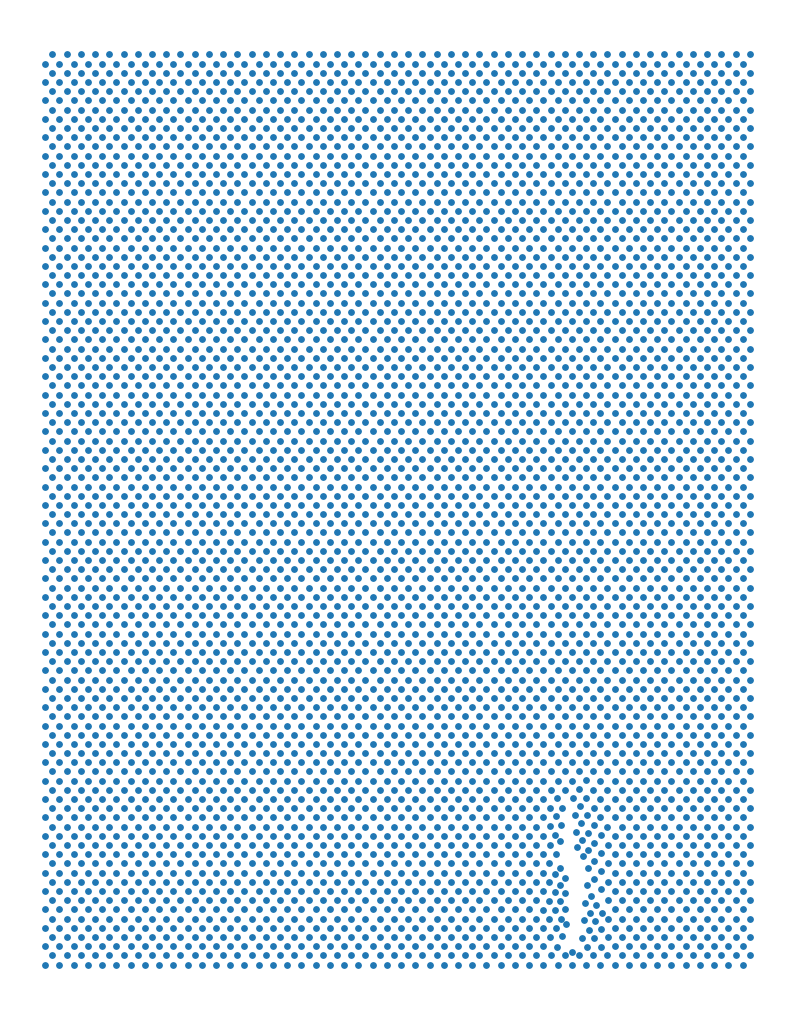

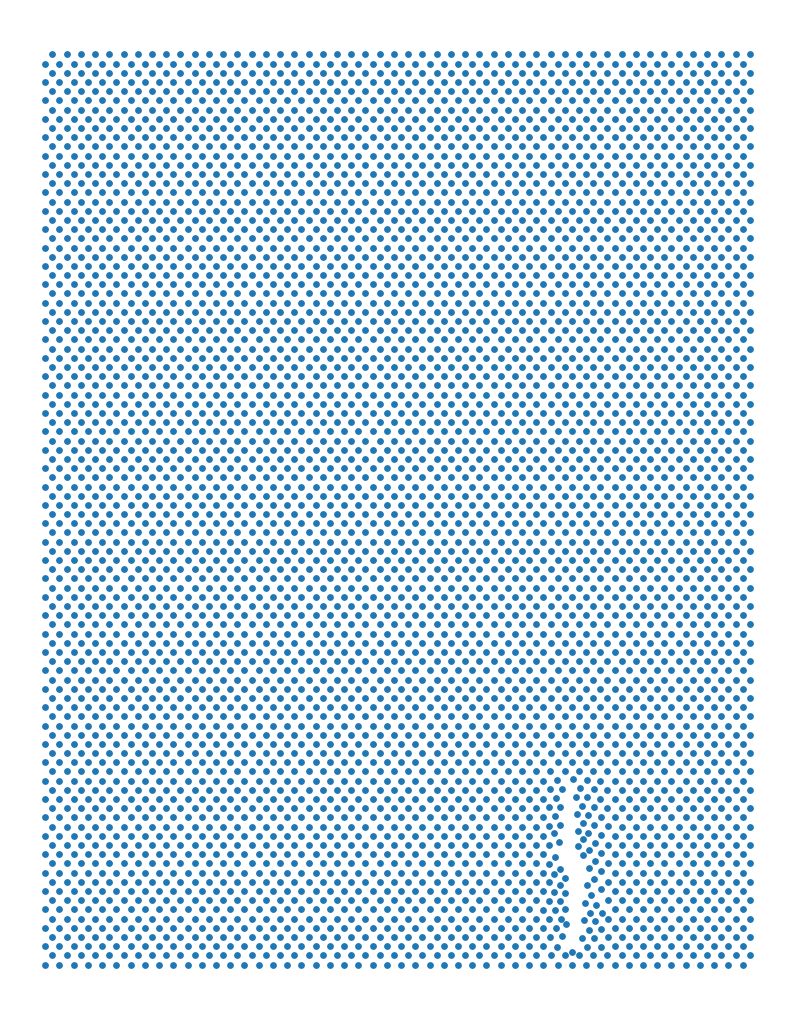

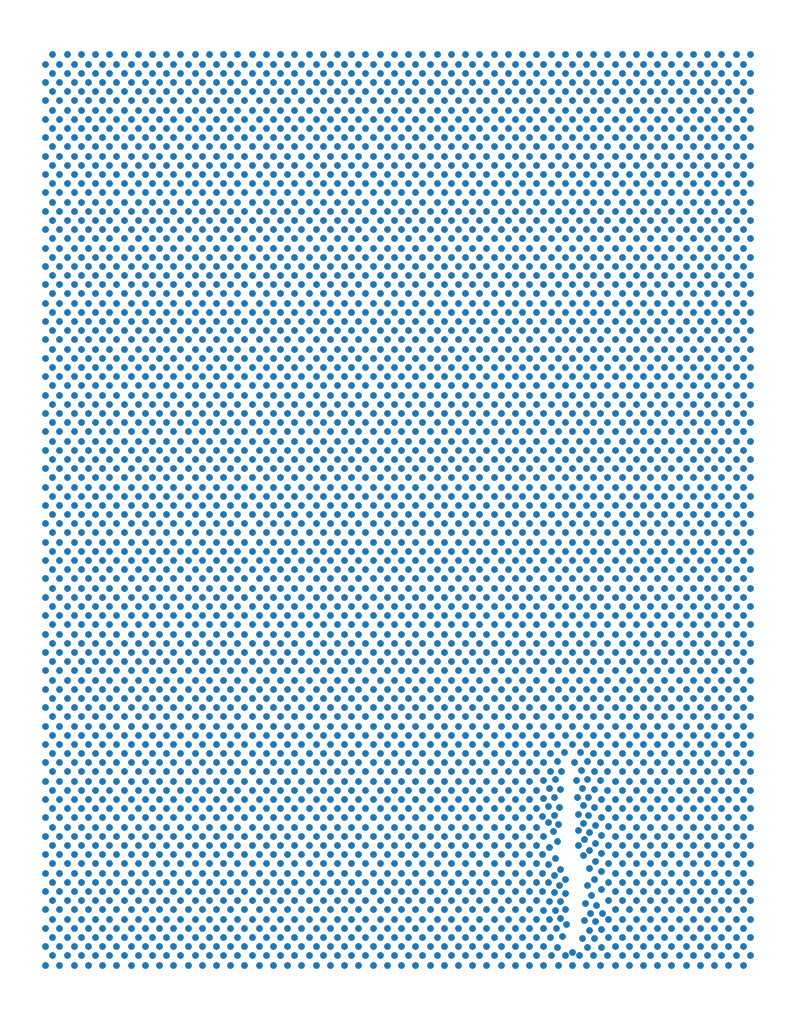

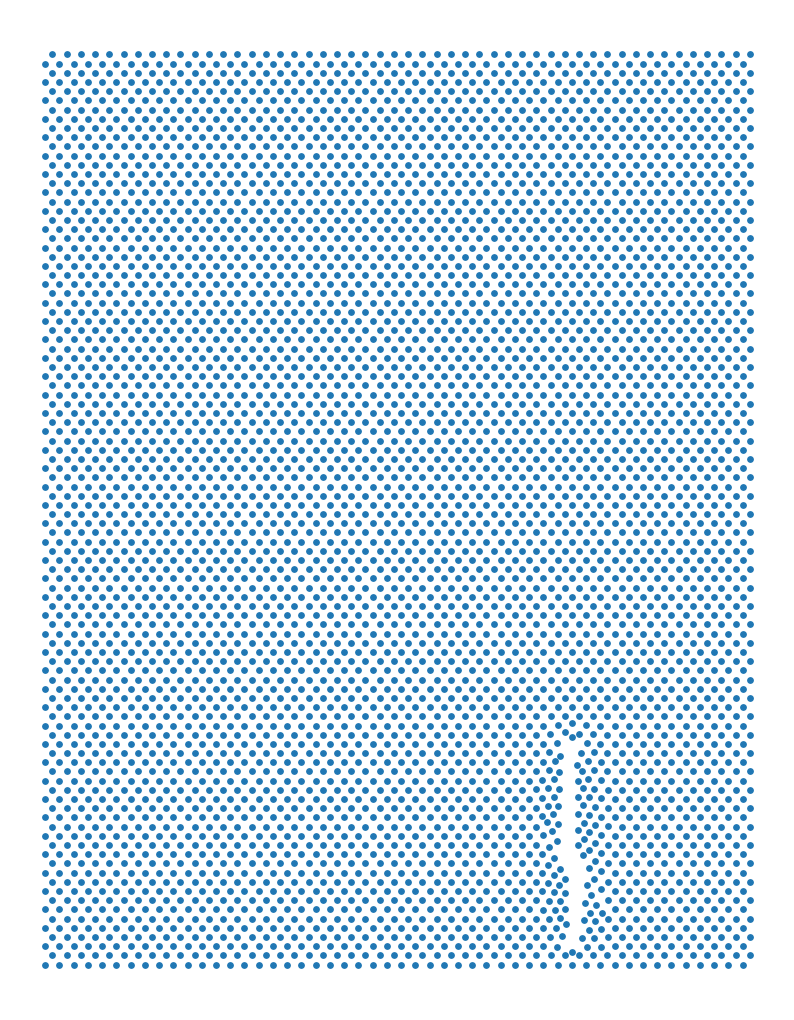

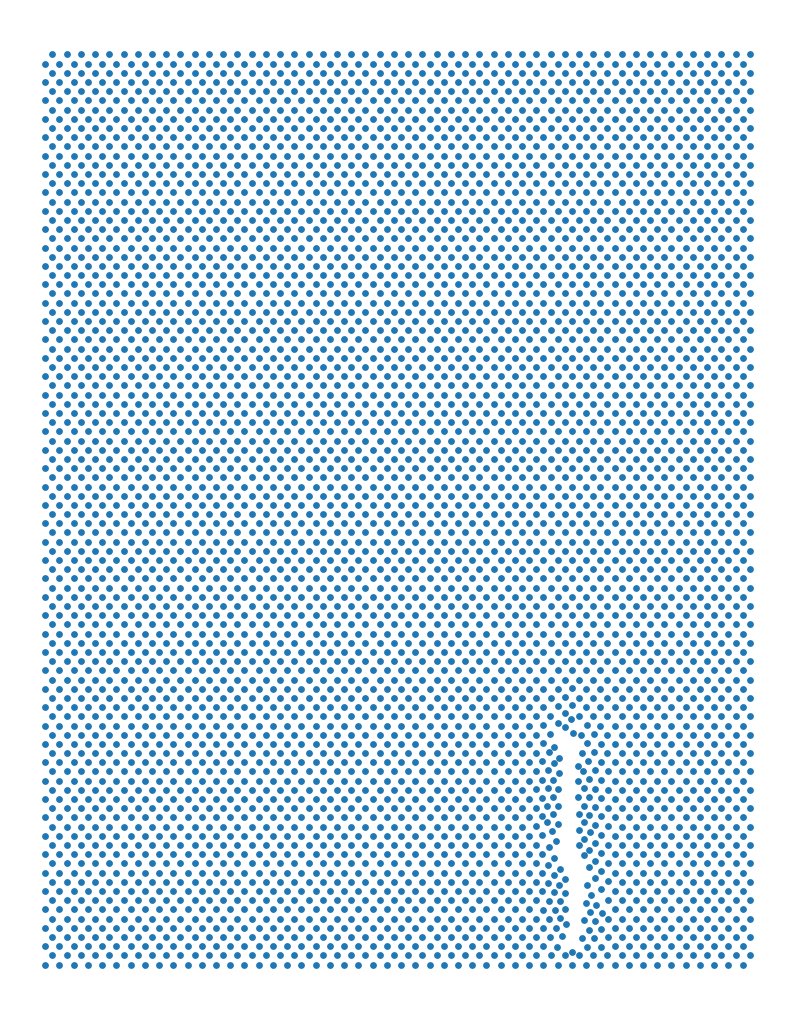

In [21]:
for h in range(50):
    mbreak = 0
    spring_to_break = 0
    spring_x, spring_y = 0, 0
    # using var_i = var[h][i][j] while iterating over the array will give you a new value of var_i
    
    run_simulation()
    
    for i in range(2,n-2): 
        for j in range(2,n-2):
            #var_i = var[h][i][j]
            if lattice[i][j].all()!=0:
                fracturing(i, j)
                
    if (spring_to_break != 0):
        
        for nb in adjacent[spring_x][spring_y]:
            if (adjacent[nb[0]][nb[1]] != 0.0): # if nb = 0.0 then its wall
                if nb == spring_to_break:
                    adjacent[nb[0]][nb[1]].remove((spring_x,spring_y))
                    adjacent[spring_x][spring_y].remove(nb)

    
    # make a plot every 5 steps
    if (h%5==0):
        x = lattice[:, :, 0]
        x = x[x!=0]
        y = lattice[:, :, 1]
        y = y[y!=0]

        plt.axis('off')
        plt.rcParams["figure.figsize"] = (10,13)
        plt.scatter(x, y, s = 15)
        plt.show()